## Author: Gabriel Vance
## Class: DSC530 - Data Exporation and Analysis
## Professor: Matthew Metzger
## Date: April 18, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 5 & 6 of the class. Data must be present within the folder that this notebook is run in.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Chapter 5, Exercise 1
## Plot the rolling 20-day minimum of the Facebook closing price using pandas.


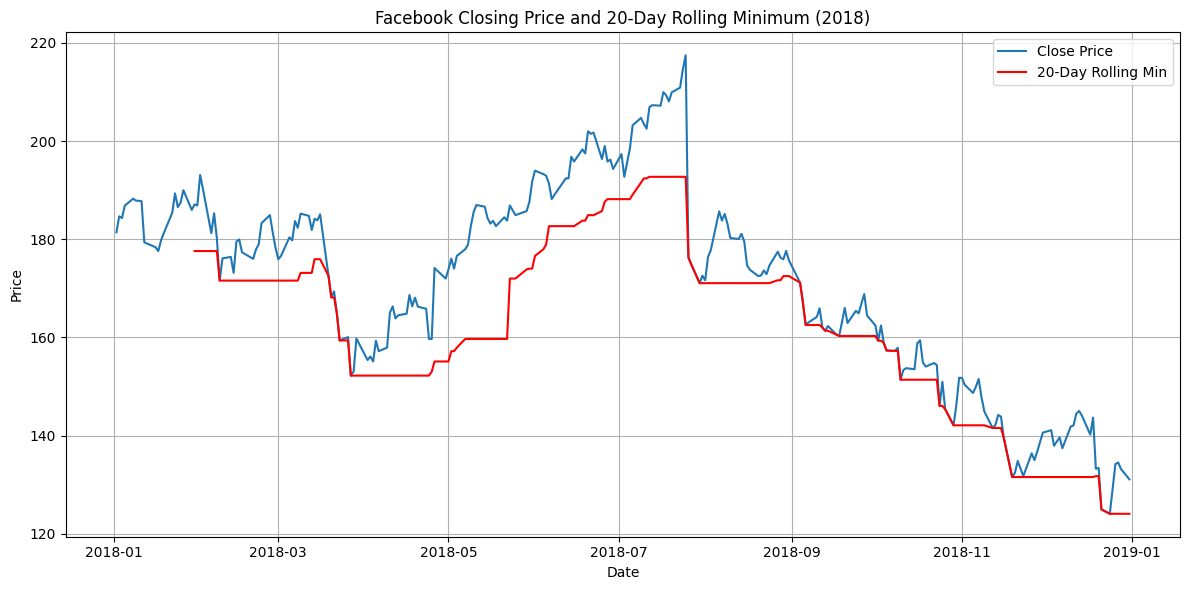

In [13]:
# Load the data
fb_df = pd.read_csv("fb_stock_prices_2018.csv")

# Ensure correct datetime format and sort by date
fb_df['date'] = pd.to_datetime(fb_df['date'])
fb_df = fb_df.sort_values('date')

# Calculate the rolling 20-day minimum of the closing price
fb_df['20_day_min'] = fb_df['close'].rolling(window=20).min()

# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(fb_df['date'], fb_df['close'], label='Close Price')
plt.plot(fb_df['date'], fb_df['20_day_min'], label='20-Day Rolling Min', color='red')
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Facebook Closing Price and 20-Day Rolling Minimum (2018)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Chapter 5, Exercise 2
## Create a histogram and KDE of the change from open to close in the price of Facebook stock.


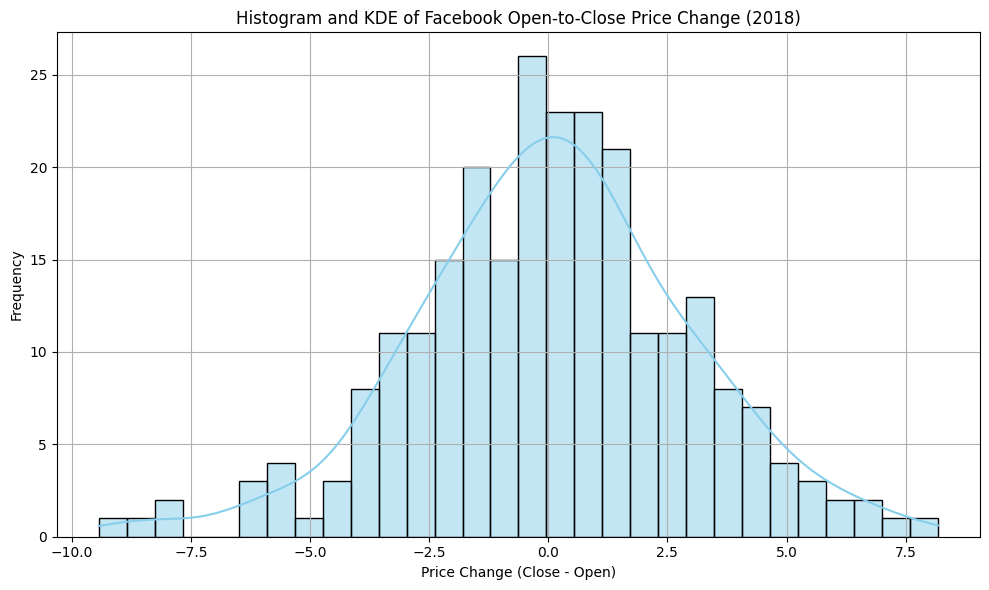

In [14]:
# Calculate daily change from open to close
fb_df['open_close_change'] = fb_df['close'] - fb_df['open']

# Plot histogram and KDE
plt.figure(figsize=(10, 6))
sns.histplot(fb_df['open_close_change'], kde=True, bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram and KDE of Facebook Open-to-Close Price Change (2018)')
plt.xlabel('Price Change (Close - Open)')
plt.ylabel('Frequency')
plt.grid(True)
plt.tight_layout()
plt.show()

# Chapter 5, Exercise 3
## Using the earthquake data, create box plots for the magnitudes of each magType used in Indonesia.



/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_10473/2310684735.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=indonesia_df, x='magType', y='mag', palette='Set2')


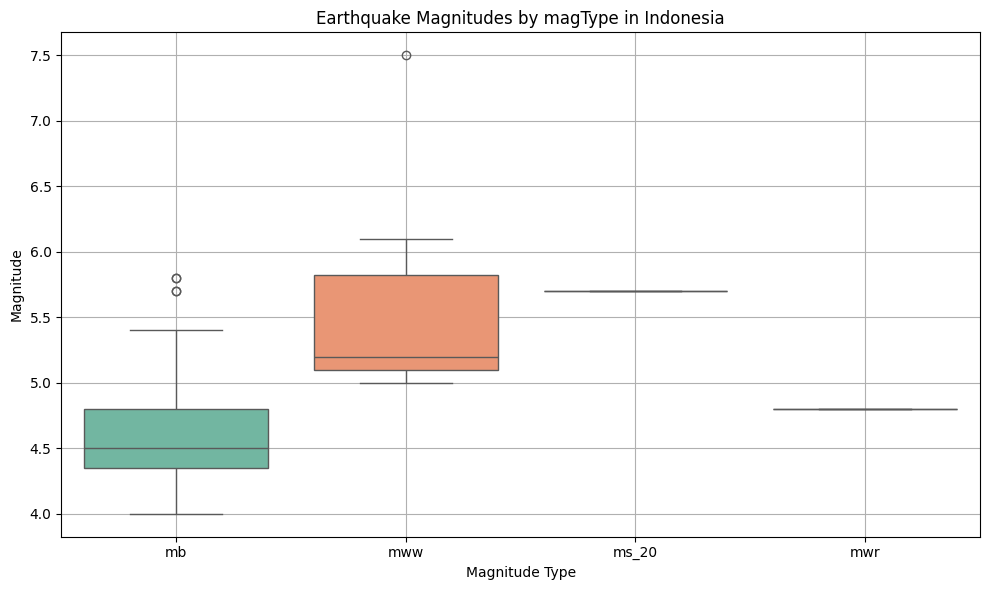

In [15]:
earthquake_df= pd.read_csv("earthquakes.csv")


# Filter for Indonesia only
indonesia_df = earthquake_df[earthquake_df['parsed_place'] == 'Indonesia']

# Drop rows with missing magnitudes or magType (if any)
indonesia_df = indonesia_df.dropna(subset=['mag', 'magType'])

# Create box plots of magnitude by magType
plt.figure(figsize=(10, 6))
sns.boxplot(data=indonesia_df, x='magType', y='mag', palette='Set2')
plt.title('Earthquake Magnitudes by magType in Indonesia')
plt.xlabel('Magnitude Type')
plt.ylabel('Magnitude')
plt.grid(True)
plt.tight_layout()
plt.show()

# Chapter 5, Exercise 4
## Make a line plot of the difference between the weekly maximum high price and the weekly minimum low price for Facebook. This should be a single line.

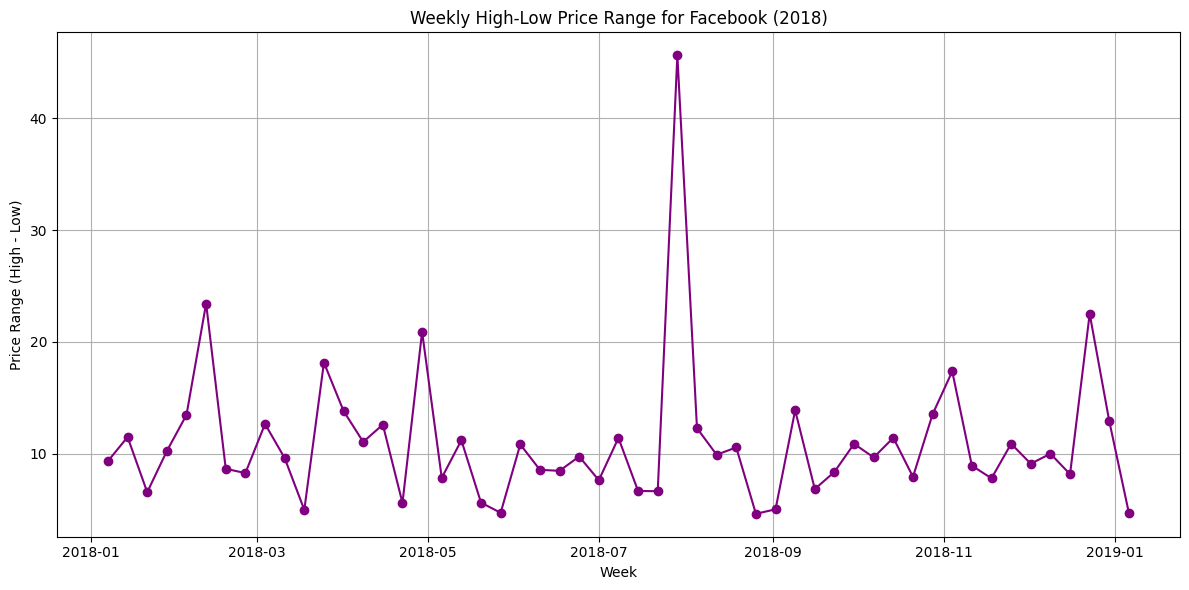

In [16]:
# Convert date column to datetime and set as index
fb_df['date'] = pd.to_datetime(fb_df['date'])
fb_df.set_index('date', inplace=True)

# Resample weekly and calculate max high and min low
weekly_high = fb_df['high'].resample('W').max()
weekly_low = fb_df['low'].resample('W').min()

# Calculate the weekly price range
weekly_range = weekly_high - weekly_low

# Plot the result
plt.figure(figsize=(12, 6))
plt.plot(weekly_range.index, weekly_range, marker='o', linestyle='-', color='purple')
plt.title('Weekly High-Low Price Range for Facebook (2018)')
plt.xlabel('Week')
plt.ylabel('Price Range (High - Low)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Chapter 6, Exercise 1
## Using seaborn, create a heatmap to visualize the correlation coefficients between earthquake magnitude and whether there was a tsunami for earthquakes measured with the mb magnitude type.

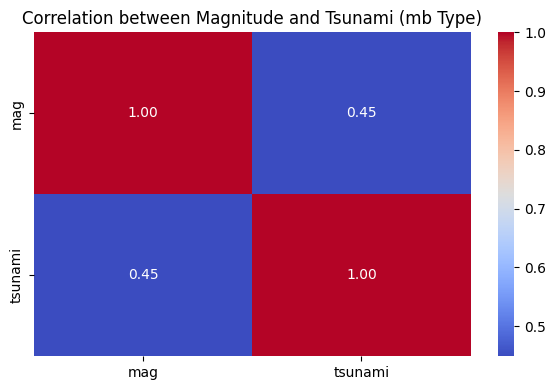

In [17]:
# Filter for magType 'mb'
mb_df = earthquake_df[earthquake_df['magType'] == 'mb']

# Drop rows with missing values in 'mag' or 'tsunami'
mb_df = mb_df[['mag', 'tsunami']].dropna()

# Compute correlation matrix
correlation = mb_df.corr()

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Correlation between Magnitude and Tsunami (mb Type)')
plt.tight_layout()
plt.show()

# Chapter 6, Exercise 2
## Create a box plot of Facebook volume traded and closing prices and draw reference lines for the bounds of a Tukey fence with a multiplier of 1.5. The bounds will be at Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. Be sure to use the quantile() method on the data to make this easier. Pick whichever orientation you prefer for the plot, but make sure to use subplots.


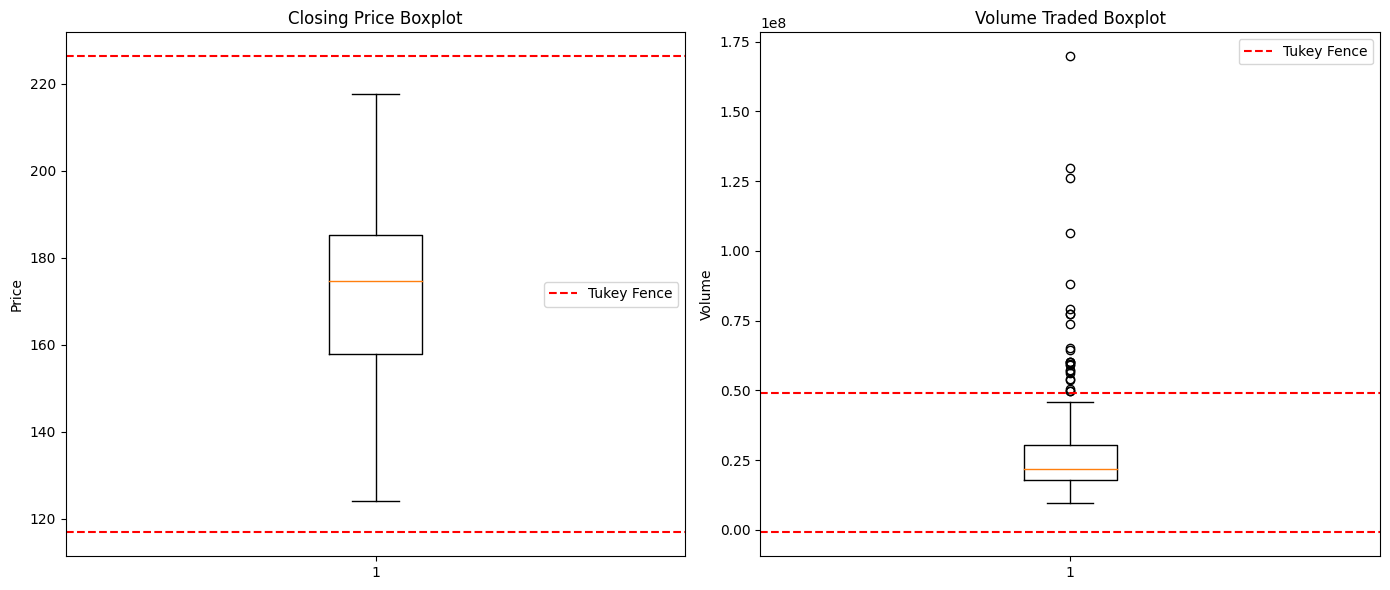

In [18]:
# Calculate stats and Tukey bounds for 'close'
q1_close = fb_df['close'].quantile(0.25)
q3_close = fb_df['close'].quantile(0.75)
iqr_close = q3_close - q1_close
lower_close = q1_close - 1.5 * iqr_close
upper_close = q3_close + 1.5 * iqr_close

# Calculate stats and Tukey bounds for 'volume'
q1_volume = fb_df['volume'].quantile(0.25)
q3_volume = fb_df['volume'].quantile(0.75)
iqr_volume = q3_volume - q1_volume
lower_volume = q1_volume - 1.5 * iqr_volume
upper_volume = q3_volume + 1.5 * iqr_volume

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot for 'close'
axes[0].boxplot(fb_df['close'], vert=True)
axes[0].axhline(lower_close, color='red', linestyle='--', label='Tukey Fence')
axes[0].axhline(upper_close, color='red', linestyle='--')
axes[0].set_title('Closing Price Boxplot')
axes[0].set_ylabel('Price')
axes[0].legend()

# Boxplot for 'volume'
axes[1].boxplot(fb_df['volume'], vert=True)
axes[1].axhline(lower_volume, color='red', linestyle='--', label='Tukey Fence')
axes[1].axhline(upper_volume, color='red', linestyle='--')
axes[1].set_title('Volume Traded Boxplot')
axes[1].set_ylabel('Volume')
axes[1].legend()

plt.tight_layout()
plt.show()